Here I try to implement the method successfully applied in the file PINNverse_two_qubits_time_dependent_Lindblad_HXYZ_Gemini_3_stages_final.ipynb to the problem described in Reginaldo's draft:

<img src="../figs/ReginaldoDraft.png" style="width: 30%; height: auto;">

In [1]:
import torch as tc
import numpy as np
from scipy.interpolate import CubicSpline
from scipy.integrate import cumulative_simpson, solve_ivp
import matplotlib.pyplot as plt
from tqdm import tqdm
from mpmath import polygamma, mpc
import torch.nn as nn
from scipy.interpolate import CubicSpline

import sys
import os
sys.path.insert(0, '../src')
import function as my

device = tc.device('cuda' if tc.cuda.is_available() else 'cpu')
print(f"Executing in device: {device}")

if device.type == 'cpu':
  num_threads = 10
  tc.set_num_threads(num_threads)
  tc.set_num_interop_threads(num_threads)
  print(f"Threads set to: {tc.get_num_threads()}")


Executing in device: cpu
Threads set to: 10


First, I have to generate the data. For this, I consider a thermal bath with an Ohmic spectral density

$
J(\omega)= \, \eta \, \omega \, e^{-\omega/\omega_c}.
$

For this, the noise correlation function is given by

$
C(t)=\frac{\eta}{( \beta \hbar )^{2}}\left\{\Psi _{1}\left(\frac{1+i\omega _{c} t}{\beta \hbar \omega _{c}}\right) +\xi \left( 2,1+\frac{1-i\omega _{c} t}{\beta \hbar \omega _{c}}\right)\right\},
$

where $\Psi _{1}(.)$ is the $2^{nd}$ logarithmic derivative of the Gamma function and $\xi(.,.)$ the Hurwitz zeta function.

In [2]:
def corrfun(t, params):
    wc, beta, eta = params["wc"], params["beta"], params["eta"]
    z1 = mpc(1 + 1j*wc*t) / (beta*wc)
    z2 = 1 + (1 - 1j*wc*t) / (beta*wc)
    y = (eta/(beta*beta)) * (polygamma(1, z1) + polygamma(1, z2))
    return float(y.real), float(y.imag)

Set the system parameters: the thermal bath parameters defined above, and the driving frequency.

In [3]:
sysparams = {"wc": 1., "beta": 1., "eta": 1., "freq": 0.5, "Nivals": 6}
tlist = np.linspace(0, 10, 500)

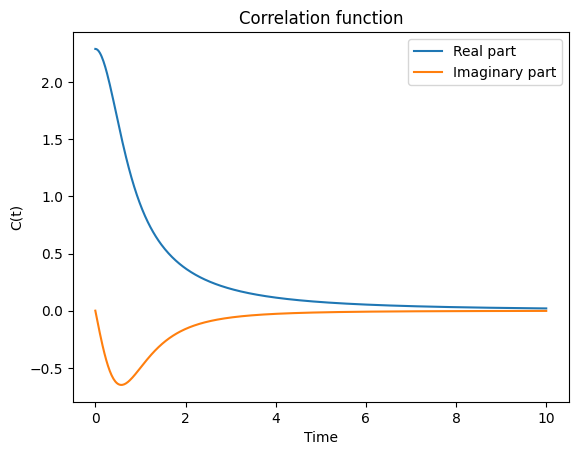

In [4]:
plt.plot(tlist, [corrfun(t, sysparams) for t in tlist], label=["Real part", "Imaginary part"])
plt.title("Correlation function")
plt.xlabel("Time")
plt.ylabel("C(t)")
plt.legend()
plt.show()

Now, define the fields that appear in the motion equations from for the observables (see Eq. (28) from the draft).

In [4]:
def make_integral_function(fun, t_grid, params):
    freq = params["freq"]
    
    # Evaluate the correlation function on the grid
    cr = np.array([fun(t, params) for t in t_grid])

    # Evaluate the different functions to be integrated on the grid
    Gam = cr[:,0]*np.cos(freq*t_grid)
    Lam = cr[:,1]*np.sin(freq*t_grid)
    Del = cr[:,0]*np.sin(freq*t_grid)

    # Cumulative integral from t_grid[0] to each grid point
    integral_vals_Gam = cumulative_simpson(Gam, x=t_grid, initial=0)
    integral_vals_Lam = cumulative_simpson(Lam, x=t_grid, initial=0)
    integral_vals_Del = cumulative_simpson(Del, x=t_grid, initial=0)

    # Build the cubic spline interpolator
    spline_Gam = CubicSpline(t_grid, integral_vals_Gam)
    spline_Lam = CubicSpline(t_grid, integral_vals_Lam)
    spline_Del = CubicSpline(t_grid, integral_vals_Del)

    return spline_Gam, spline_Lam, spline_Del

In [5]:
Gam, Lam, Del = make_integral_function(corrfun, tlist, sysparams)

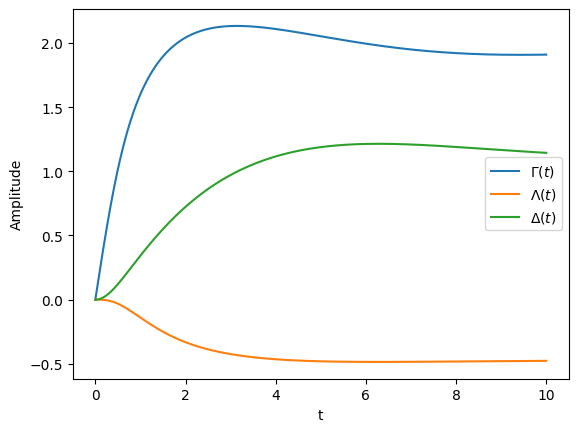

In [7]:
fig, ax = plt.subplots()
ax.plot(tlist, Gam(tlist), label=fr"$\Gamma(t)$")
ax.plot(tlist, Lam(tlist), label=fr"$\Lambda(t)$")
ax.plot(tlist, Del(tlist), label=fr"$\Delta(t)$")
ax.set_xlabel("t")
ax.set_ylabel("Amplitude")
ax.legend(loc="center right")

Now, define a set of single-qubit initial states through their polarization and solve the initial-value problem for the mean values of the Pauli matrices. The $\sigma_y$ and $\sigma_z$ matrices are transformed to a frame that rotates with respect to the $x$ axis with frequency $\Omega$:

$u(t)=\langle e^{{i\Omega t \sigma_x /2}}\sigma_y e^{{-i\Omega t \sigma_x/2}} \rangle$

$v(t)=\langle e^{{i\Omega t \sigma_x/2}}\sigma_z e^{{-i\Omega t \sigma_x/2}} \rangle$

In [6]:
def InValProb_rhs(t, u, Gam, Lam, Del, freq):
    du = np.zeros_like(u)

    du[0] = -Gam(t)*u[0] + Lam(t)
    du[1] = -Gam(t)*u[1] - (Del(t) + freq)*u[2]
    du[2] = freq*u[1]

    return du

In [7]:
np.random.seed(42)  # Set a seed for reproducibility
k = 0
stsdyn = []
ist = []
while (k < sysparams["Nivals"]):
    p = np.random.normal(0.5, 1, 3)# Random vector for the polarization of the initial state
    if (p.dot(p) < 1.):
        k += 1

        sol = solve_ivp(
            fun=lambda t, u: InValProb_rhs(t, u, Gam, Lam, Del, sysparams["freq"]),
            t_span=(tlist[0], tlist[-1]),#Note the final time goes first
            y0=p,
            dense_output=True
        )

        ist.append(p)
        stsdyn.append(sol.sol(tlist))  # Store the solution for this initial state

stsdyn = np.vstack(stsdyn)
Obs = tc.tensor(stsdyn.T, device = device)

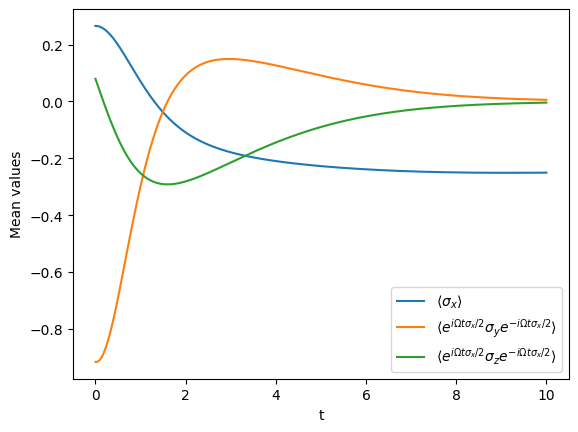

In [8]:
istate = 5

fig, ax = plt.subplots()
ax.plot(tlist, stsdyn[3*istate, :], label=fr"$\langle \sigma_x \rangle$")
ax.plot(tlist, stsdyn[3*istate+1, :], label=fr"$\langle e^{{i\Omega t \sigma_x /2}}\sigma_y e^{{-i\Omega t \sigma_x/2}} \rangle$")
ax.plot(tlist, stsdyn[3*istate+2, :], label=fr"$\langle e^{{i\Omega t \sigma_x/2}}\sigma_z e^{{-i\Omega t \sigma_x/2}} \rangle$")
ax.set_xlabel("t")
ax.set_ylabel("Mean values")
ax.legend()

Let's start with the neural networks approach.

In [9]:
class FourierFeatures(nn.Module):
    def __init__(self, n_freq=16, f_max=3.0, trainable=False):
        super().__init__()
        # Frequências baixas e igualmente espaçadas (de 0.1*f_max até f_max)
        freqs = tc.linspace(0.1 * f_max, f_max, n_freq).unsqueeze(1) # Shape: (n_freq, 1)
        # Fixar trainable=False para impedir que o otimizador crie frequências espúrias
        self.B = nn.Parameter(freqs, requires_grad=trainable)

    def forward(self, t):
        if t.dim() == 1:
            t = t[:, None]
        # t: (N, 1), B: (n_freq, 1) -> x: (N, n_freq)
        x = t @ self.B.T
        return tc.cat([tc.sin(x), tc.cos(x)], dim=-1)
class Rede(nn.Module):
    def __init__(self, neuronio, activation, input_=1, output_=1,
                 creat_p=False, N_of_paramater=1, dropout_prob=0.0,
                 use_fourier=False, n_freq=32, f_max=10.0):
        super().__init__()

        self.neuronio = neuronio
        self.output = output_
        self.creat_p = creat_p
        self.N_of_paramater = N_of_paramater
        self.dropout_prob = dropout_prob
        self.use_fourier = use_fourier

        if use_fourier:
            # CHAMADA CORRIGIDA AQUI:
            self.ff = FourierFeatures(n_freq=n_freq, f_max=f_max, trainable=False)
            first_in = 2 * n_freq
        else:
            self.ff = None
            first_in = input_

        self.hidden_layers = nn.ModuleList([nn.Linear(first_in, neuronio[0])])
        self.hidden_layers.extend(
            [nn.Linear(neuronio[_], neuronio[_+1]) for _ in range(len(neuronio)-1)]
        )
        self.output_layer = nn.Linear(neuronio[-1], output_)

        self.activation_ = activation
        self.dropouts = nn.ModuleList([nn.Dropout(dropout_prob) for _ in range(len(neuronio))])

        if creat_p:
            self.parametro = nn.Parameter(tc.rand(N_of_paramater))

    def forward(self, x):
        if self.ff is not None:
            x = self.ff(x)

        for layer, activation, dropout in zip(self.hidden_layers, self.activation_, self.dropouts):
            x = activation(layer(x))
            x = dropout(x)

        x = self.output_layer(x)
        return x        
    
class SIN(tc.nn.Module):
    def __init__(self):
        super(SIN, self).__init__()
    def forward(self, x):
        return tc.sin(x)

In [10]:
NUM_OBSERVAVEIS = 3
NUM_CAMPOS = 3
NUM_ESTADOS = sysparams["Nivals"]
IDX_DIVISAO_CAMPOS = NUM_ESTADOS * NUM_OBSERVAVEIS

# Rede 1: Aprende as trajetórias dos observáveis
Rede_Estados = Rede(
    neuronio=[128, 128, 128],
    input_=1,
    output_=NUM_ESTADOS * NUM_OBSERVAVEIS,
    activation=[SIN()]*3,
    creat_p=True,
    N_of_paramater=0,
    use_fourier=True,
    n_freq=16,
    f_max=3.0
).to(device)


In [11]:
# Rede 2: Aprende apenas os campos de controle
neuronio = [128, 128, 128]
"""
Rede_Campos = Rede(
    neuronio=[128, 128, 128],
    input_=1,
    output_=NUM_CAMPOS,
    activation=[SIN()]*3,
    creat_p=False,    
    use_fourier=True,
    n_freq=10,
    f_max=1.0
).to(device)
"""

Rede_Campos = my.Rede(
    neuronio    = neuronio,
    input_      = 1,
    output_     = NUM_CAMPOS,
    activation  =[tc.nn.Tanh()]*len(neuronio),
    creat_p     =True,
    N_of_paramater= 0)

#I try with an architechture without Fourier features, since the fields are expected to be smooth functions of time
time =  tc.linspace(
        0,
        tlist[-1],
        len(tlist),
        dtype   = tc.float32,
        #requires_grad = True,
        device=device).reshape((-1, 1))

In [12]:
def phys_res(X, dX_dt, Omega, fields):
    dsigma_x_dt, dsigma_y_dt, dsigma_z_dt = [dX_dt[:, i:i+1] for i in range(3)]
    sigma_x, sigma_y, sigma_z = [X[:, i:i+1] for i in range(3)]
    Gamma, Lambda, Delta = fields

    # Compute the residuals based on the differential equations
    res = (dsigma_x_dt + Gamma * sigma_x - Lambda)**2
    res += (dsigma_y_dt + Gamma * sigma_y + (Delta + Omega) * sigma_z)**2
    res += (dsigma_z_dt - Omega * sigma_y)**2

    return res

In [13]:
print("Computing derivatives from a neural network for the observables.")

opt_observables = tc.optim.Adam(Rede_Estados.parameters(), lr=1e-3)
scheduler_obs = tc.optim.lr_scheduler.ReduceLROnPlateau(opt_observables, mode='min', factor=0.5, patience=200)

best_val_loss = float("inf")
best_state = None
early_stop_patience = 200
epochs_without_improvement = 0
min_delta = 1e-8

#Split into training and validation sets to avoid overfitting noisy data
N = len(tlist)
n_val = int(N * 0.3)
n_train = N - n_val

idx = np.arange(N)

np.random.shuffle(idx)# This function shuffles the indices of the data points.
idx_train = tc.as_tensor(idx[:n_train], dtype=tc.long, device=device)
idx_val   = tc.as_tensor(idx[n_train:], dtype=tc.long, device=device)
times_train = time[idx_train]
times_val   = time[idx_val]
times_train = times_train.detach()
times_val = times_val.detach()
LOSS_TRAIN = []
LOSS_VAL = []
#opt_ids = {id(p) for g in opt_observables.param_groups for p in g["params"]}
#model_ids = {id(p) for p in Rede_Estados.parameters()}
#print(len(opt_ids), len(model_ids), opt_ids == model_ids)
#print(opt_observables.param_groups[0]["lr"])
#common = opt_ids & model_ids
#print("shared:", len(common))
#for name, p in Rede_Estados.named_parameters():
#    print(name, tuple(p.shape), id(p) in opt_ids)
#opt_ids = {id(p) for g in opt_observables.param_groups for p in g["params"]}
#for name, obj in list(globals().items()):
#    if isinstance(obj, nn.Module):
#        ids = {id(p) for p in obj.parameters()}
#        print(name, len(ids), len(ids & opt_ids))
for epoca in range(200):
    Rede_Estados.train()
    opt_observables.zero_grad()
    y_pred = Rede_Estados(times_train)
    loss_estados = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS
        y_cond = Obs[idx_train, 3*estado_idx:3*estado_idx+3]
        y_pred_cond = y_pred[:, idx_start:idx_end]
        loss_estados += ((y_pred_cond - y_cond) ** 2).mean()
    loss_estados /= NUM_ESTADOS
    LOSS_TRAIN.append(loss_estados.item())
    loss_estados.backward()
    #grads = [
    #    p.grad.detach().flatten()
    #    for p in Rede_Estados.parameters()
    #    if p.grad is not None
    #]
    #grad_norm = tc.cat(grads).norm(p=2) if grads else tc.tensor(0.0)
    #print(grad_norm.item())
    #params_before = [
    #    p.detach().clone()
    #    for p in Rede_Estados.parameters()
    #]
    opt_observables.step()
    #max_update = max(
    #    (p.detach() - p0).abs().max().item()
    #    for p, p0 in zip(Rede_Estados.parameters(), params_before)
    #    if p.numel() > 0
    #)
    #print("loss:", loss_estados.item(), "max update:", max_update)
    Rede_Estados.eval()
    #Early stopping using validation loss.
    with tc.no_grad():
        y_val_pred = Rede_Estados(times_val)
        loss_val = 0.0
        for estado_idx in range(NUM_ESTADOS):
            idx_start = estado_idx * NUM_OBSERVAVEIS
            idx_end = idx_start + NUM_OBSERVAVEIS
            y_val_cond = Obs[idx_val, 3*estado_idx:3*estado_idx+3]
            y_val_pred_cond = y_val_pred[:, idx_start:idx_end]
            loss_val += ((y_val_pred_cond - y_val_cond) ** 2).mean()
        loss_val /= NUM_ESTADOS
    val_value = loss_val.item()
    LOSS_VAL.append(val_value)
    if val_value < best_val_loss - min_delta:
        best_val_loss = val_value
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in Rede_Estados.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
    if epochs_without_improvement >= early_stop_patience:
        print(f"Early stopping at epoch {epoca}; best validation loss = {best_val_loss:.3e}")
        break
    scheduler_obs.step(loss_val)
    #scheduler_obs.step(loss_estados)
    if (epoca + 1) % 500 == 0:
        print(f"Epoch {epoca+1} | Loss Estados: {loss_val.item():.2e}")
Rede_Estados.load_state_dict(best_state)
Rede_Estados.train()
time_grad = time.detach().clone().requires_grad_(True)
y_fixo = Rede_Estados(time_grad)
dX_dt_fixo = tc.cat([
    tc.autograd.grad(
        outputs=y_fixo[:, j],
        inputs=time_grad,
        grad_outputs=tc.ones_like(y_fixo[:, j]),
        create_graph=False,
        retain_graph=True
    )[0]
    for j in range(y_fixo.shape[1])
], dim=1)
y_fixo_np = y_fixo.detach().cpu().numpy()
dX_dt_fixo_np = dX_dt_fixo.detach().cpu().numpy()

Computing derivatives from a neural network for the observables.


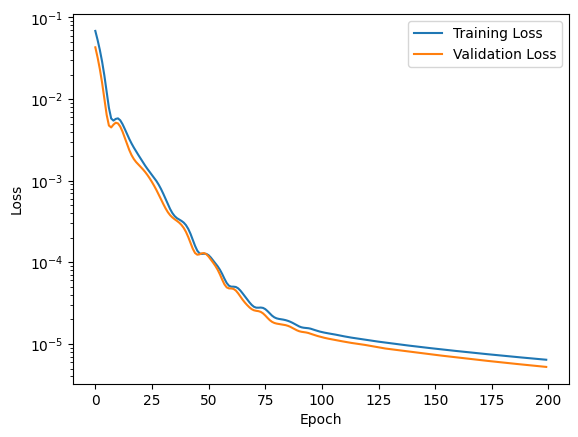

In [14]:
plt.plot(LOSS_TRAIN, label='Training Loss')
plt.plot(LOSS_VAL, label='Validation Loss')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

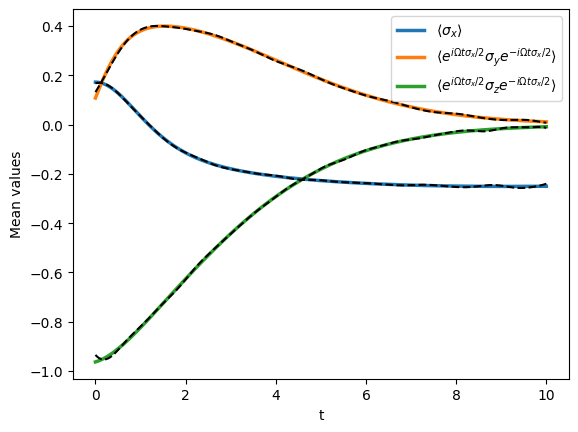

In [19]:
istate = 4 

fig, ax = plt.subplots()

ax.plot(tlist, stsdyn[3*istate, :], label=fr"$\langle \sigma_x \rangle$", lw=2.5)
ax.plot(tlist, stsdyn[3*istate+1, :], label=fr"$\langle e^{{i\Omega t \sigma_x /2}}\sigma_y e^{{-i\Omega t \sigma_x/2}} \rangle$", lw=2.5)
ax.plot(tlist, stsdyn[3*istate+2, :], label=fr"$\langle e^{{i\Omega t \sigma_x/2}}\sigma_z e^{{-i\Omega t \sigma_x/2}} \rangle$", lw=2.5)
for i in range(3):
    ax.plot(tlist, y_fixo_np[:, istate * NUM_OBSERVAVEIS + i], 'k--')

ax.set_xlabel("t")
ax.set_ylabel("Mean values")
ax.legend()

Starting optimization of a neural network for the fields, keeping the driving frequency equal to zero.
y_fixo False None
dX_dt_fixo False None
time False None
param_qutip False None


/home/martin/miniconda3/lib/python3.13/site-packages/torch/optim/lr_scheduler.py:1694: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  current = float(metrics)


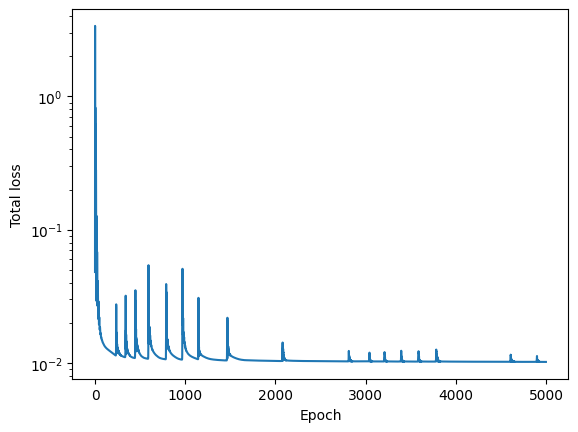

In [15]:
print("Starting optimization of a neural network for the fields, keeping the driving frequency equal to zero.")
y_fixo = y_fixo.detach()
#time = time.detach().requires_grad_(True)
opt_campos = tc.optim.Adam(Rede_Campos.parameters(), lr=5e-3)
scheduler_cam = tc.optim.lr_scheduler.ReduceLROnPlateau(opt_campos, mode='min', factor=0.5, patience=200)

param_qutip = tc.tensor([0.0], device=device)
#param_qutip = Rede_Campos.parametro

LOSS = []

for n, t in [("y_fixo", y_fixo), ("dX_dt_fixo", dX_dt_fixo), ("time", time), ("param_qutip", param_qutip)]:
    print(n, t.requires_grad, t.grad_fn)

for epoca in range(5000):
    opt_campos.zero_grad()
    
    # Rede de campos prevê J(t)
    z = Rede_Campos(time)
    j_fields = [z[:, i:i+1] for i in range(NUM_CAMPOS)]

    loss_edo = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS

        y_cond = y_fixo[:, idx_start:idx_end]
        dX_dt_cond = dX_dt_fixo[:, idx_start:idx_end]

        residuos = phys_res(y_cond, dX_dt_cond, param_qutip, j_fields)
        loss_edo += residuos.mean()

    loss_edo /= NUM_ESTADOS
    """
    dz = tc.cat([
        tc.autograd.grad(
            outputs=z[:, j],
            inputs=time_grad,
            grad_outputs=tc.ones_like(z[:, j]),
            create_graph=False,
            retain_graph=True
        )[0]
        for j in range(z.shape[1])
    ], dim=1)
    """
    #aux_loss = ((dz[:, 0]*tc.sin(param_qutip*time) - z[:, 2]*tc.cos(param_qutip*time))**2).mean()
    loss_endpts = (z[0, 0:3]**2).mean() + (((z[0, 1:3]-z[1, 1:3])/(time[1, 0]-time[0, 0]))**2).mean()
    loss_total = loss_edo + 0.5*loss_endpts# + aux_loss

    loss_total.backward()
    opt_campos.step()
    scheduler_cam.step(loss_total)

    LOSS.append(loss_total.item())
    #if (epoca + 1) % 500 == 0:
    #    print(f"Época {epoca+1} | Loss EDO: {loss_total.item():.2e}")

plt.plot(LOSS)
plt.yscale('log')
plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.show()

[0.]


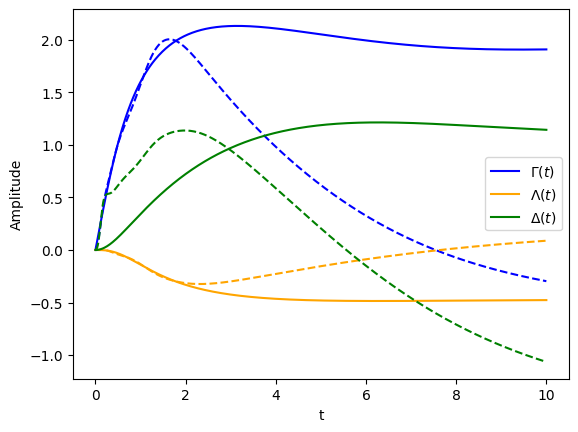

In [54]:
X_=Rede_Campos(time).cpu().detach().numpy()

fig, ax = plt.subplots()
ax.plot(tlist, Gam(tlist), "b", label=fr"$\Gamma(t)$")
ax.plot(tlist, X_[:,0],"b--")
ax.plot(tlist, Lam(tlist), color="orange", label=fr"$\Lambda(t)$")
ax.plot(tlist, X_[:,1], "--", color="orange")
ax.plot(tlist, Del(tlist), color="g", label=fr"$\Delta(t)$")
ax.plot(tlist, X_[:,2],"g--")

ax.set_xlabel("t")
ax.set_ylabel("Amplitude")
ax.legend(loc="center right")
print(param_qutip.detach().cpu().numpy())

In [16]:
# ==============================================================================
# FASE 3A: Otimizar APENAS os Gammas (Rede_Campos CONGELADA)
# ==============================================================================

param_gamma = tc.nn.Parameter(tc.tensor(1.0, device=device))

opt_gamma = tc.optim.Adam([param_gamma], lr=1e-2)

# Hiperparâmetro L1: empurrar os gammas para zero quando desnecessários
#lambda_l1 = 0e-3 

print("Fase 3A: Ajustando APENAS os Gammas (Rede_Campos congelada)...")
for epoca in range(400):
    opt_gamma.zero_grad()
    
    gammas_positivos = tc.nn.functional.softplus(param_gamma)
    
    # Avalia a Rede_Campos sem calcular gradientes para ela
    with tc.no_grad():
        z = Rede_Campos(time)
        j_fields = [z[:, i:i+1] for i in range(NUM_CAMPOS)]

    loss_edo = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS

        y_cond = y_fixo[:, idx_start:idx_end]
        dX_dt_cond = dX_dt_fixo[:, idx_start:idx_end]

        residuos = phys_res(y_cond, dX_dt_cond, param_gamma, j_fields)
        loss_edo += residuos.mean()

    loss_edo /= NUM_ESTADOS
    
    # Perda Total com Regularização L1 nos Gammas
    loss_total = loss_edo# + lambda_l1 * tc.sum(gammas_positivos)
    
    loss_total.backward()
    opt_gamma.step()

    if (epoca + 1) % 200 == 0:
        g_est = (param_gamma).detach().cpu().numpy()#tc.nn.functional.softplus(param_gamma).detach().cpu().numpy()
        print(f"Época {epoca+1} | Loss EDO: {loss_edo.item():.2e} | Gammas Estimados: {np.round(g_est, 5)}")

Fase 3A: Ajustando APENAS os Gammas (Rede_Campos congelada)...
Época 200 | Loss EDO: 6.34e-03 | Gammas Estimados: 0.19202999770641327
Época 400 | Loss EDO: 6.34e-03 | Gammas Estimados: 0.19131000339984894



Fase 3B: Otimização Concomitante Final...
None


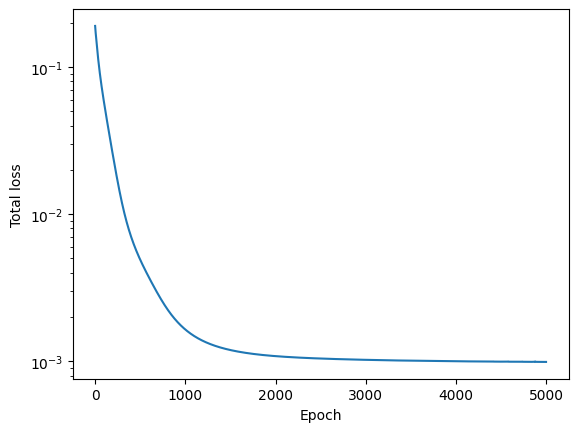

In [19]:
# ==============================================================================
# FASE 3B: Refinamento Concomitante Fino (Campos + Gammas)
# ==============================================================================
tc.autograd.set_detect_anomaly(True)
opt_conjunto = tc.optim.Adam([
    {'params': Rede_Campos.parameters(), 'lr': 5e-5}, # LR reduzido para proteger os campos
    {'params': [param_gamma],            'lr': 5e-3}
])
LOSS = []
print("\nFase 3B: Otimização Concomitante Final...")
time = time.detach().requires_grad_(True)

print(time.grad_fn)
print(loss_edo.grad_fn)
for epoca in range(5000):
    opt_conjunto.zero_grad()
    
    #gammas_positivos = tc.nn.functional.softplus(param_gamma)
    z = Rede_Campos(time)
    j_fields = j_fields = [z[:, i:i+1] for i in range(NUM_CAMPOS)]

    loss_edo = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS

        y_cond = y_fixo[:, idx_start:idx_end]
        dX_dt_cond = dX_dt_fixo[:, idx_start:idx_end]

        residuos = phys_res(y_cond, dX_dt_cond, param_gamma, j_fields)
        loss_edo += residuos.mean()

    loss_edo /= NUM_ESTADOS
    
    dz = tc.cat([
            tc.autograd.grad(
                outputs=z[:, j],
                inputs=time,
                grad_outputs=tc.ones_like(z[:, j]),
                create_graph=True,
                #retain_graph=True
            )[0]
            for j in range(z.shape[1])
    ], dim=1)

    var = dz[:, 0:1]*tc.sin(param_gamma*time) - dz[:, 2:3]*tc.cos(param_gamma*time)
    #var = tc.stack(var, dim=0)
    #print("var shape:", var.shape)
    aux_loss = (var**2).mean()
    loss_endpts = (z[0, 0:3]**2).mean() + (dz[0, 1:3]**2).mean()
    loss_total = loss_edo + 0.5*loss_endpts + aux_loss
    
    loss_total.backward()
    opt_conjunto.step()

    LOSS.append(loss_total.item())
    #if (epoca + 1) % 500 == 0:
    #    g_est = param_gamma.detach().cpu().numpy()
    #    print(f"Época {epoca+1} | Loss EDO: {loss_edo.item():.2e} | Gammas Estimados: {np.round(g_est, 5)}")

plt.plot(LOSS)
plt.yscale('log')
plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.show()

0.4834364


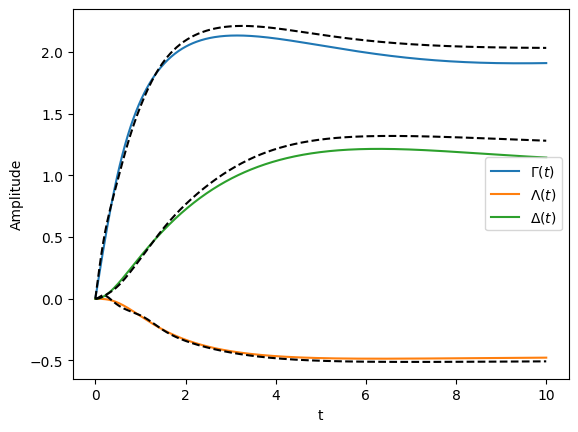

In [20]:
X_=Rede_Campos(time).cpu().detach().numpy()
Opt_Omega = param_gamma.detach().cpu().numpy()

fig, ax = plt.subplots()
ax.plot(tlist, Gam(tlist), label=fr"$\Gamma(t)$")
ax.plot(tlist, Lam(tlist), label=fr"$\Lambda(t)$")
ax.plot(tlist, Del(tlist), label=fr"$\Delta(t)$")
for i in range(NUM_CAMPOS):
    ax.plot(tlist, X_[:,i],"k--")

#ax.set_xlim(0, 1.5)
ax.set_xlabel("t")
ax.set_ylabel("Amplitude")
ax.legend(loc="center right")
print(Opt_Omega)

Now, I try to recover the observable dynamics.

In [21]:
Opt_Gam = CubicSpline(tlist, X_[:,0])
Opt_Lam = CubicSpline(tlist, X_[:,1])
Opt_Del = CubicSpline(tlist, X_[:,2])

In [22]:
recdyn = []
for k in range(sysparams["Nivals"]):
    sol = solve_ivp(
            fun=lambda t, u: InValProb_rhs(t, u, Opt_Gam, Opt_Lam, Opt_Del, Opt_Omega),
            t_span=(tlist[0], tlist[-1]),#Note the final time goes first
            y0=ist[k],
            dense_output=True
    )

    recdyn.append(sol.sol(tlist))  # Store the solution for this initial state

recdyn = np.vstack(recdyn)

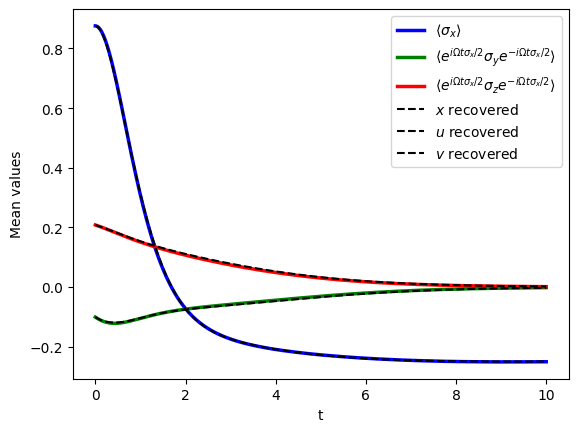

In [23]:
istate = 2

fig, ax = plt.subplots()

ax.plot(tlist, stsdyn[3*istate, :], label=fr"$\langle \sigma_x \rangle$", lw=2.5, color="blue")
ax.plot(tlist, stsdyn[3*istate+1, :], label=fr"$\langle e^{{i\Omega t \sigma_x /2}}\sigma_y e^{{-i\Omega t \sigma_x/2}} \rangle$", lw=2.5, color="green")
ax.plot(tlist, stsdyn[3*istate+2, :], label=fr"$\langle e^{{i\Omega t \sigma_x/2}}\sigma_z e^{{-i\Omega t \sigma_x/2}} \rangle$", lw=2.5, color="red")
ax.plot(tlist, recdyn[3*istate, :],"k--", label=fr"$x$ recovered")
ax.plot(tlist, recdyn[3*istate+1, :],"k--", label=fr"$u$ recovered")
ax.plot(tlist, recdyn[3*istate+2, :],"k--", label=fr"$v$ recovered")

ax.set_xlabel("t")
ax.set_ylabel("Mean values")
ax.legend()

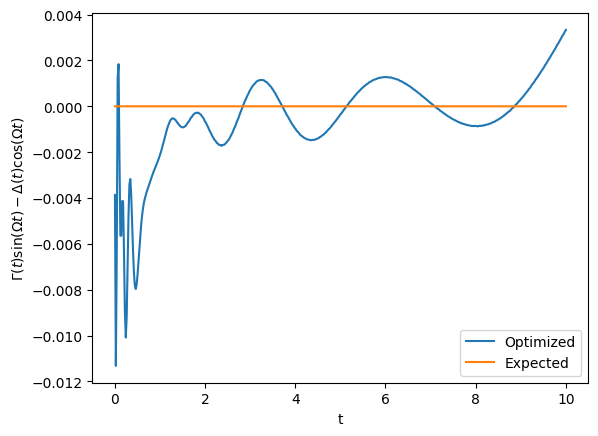

In [24]:
fig, ax = plt.subplots()

chkdiff = lambda t: Opt_Gam(t, nu = 1)*np.sin(Opt_Omega*t) - Opt_Del(t, nu = 1)*np.cos(Opt_Omega*t)

ax.plot(tlist, chkdiff(tlist), label="Optimized")
ax.plot(tlist, [Gam(t, nu = 1)*np.sin(sysparams["freq"]*t) - Del(t, nu = 1)*np.cos(sysparams["freq"]*t) for t in tlist], label="Expected")
ax.set_xlabel("t")
ax.set_ylabel(fr"$\Gamma(t)\sin(\Omega t) - \Delta(t)\cos(\Omega t)$")
ax.legend()

Now, we extract the real and imaginary part of the noise correlation function.

In [25]:
Opt_Cr = np.sqrt(Opt_Gam(tlist, nu=1)**2 + Opt_Del(tlist, nu=1)**2)

In [26]:
Opt_Ci = [Opt_Lam(t, nu=1)/np.sin(Opt_Omega*t) if (np.abs(np.sin(Opt_Omega*t)) > 1e-10 and t < 5.) else 0. for t in tlist]

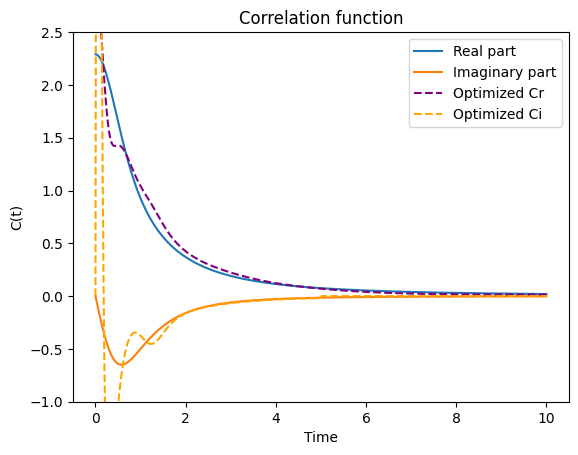

In [27]:
plt.plot(tlist, [corrfun(t, sysparams) for t in tlist], label=["Real part", "Imaginary part"])
plt.plot(tlist, Opt_Cr, label="Optimized Cr", color="purple", linestyle="--")
plt.plot(tlist, Opt_Ci, label="Optimized Ci", color="orange", linestyle="--")
plt.title("Correlation function")
plt.xlabel("Time")
plt.ylabel("C(t)")
plt.ylim(-1, 2.5)
plt.legend()
plt.show()

In [134]:
Gamdiff = lambda t: Gam(t) - Opt_Gam(t)
Lamdiff = lambda t: Lam(t) - Opt_Lam(t)
Deldiff = lambda t: Del(t) - Opt_Del(t)

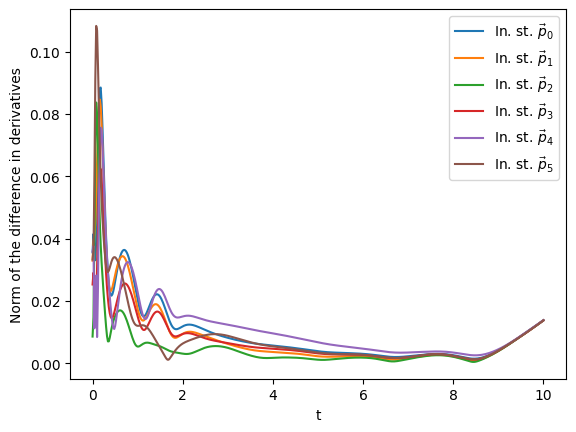

In [147]:
fig, ax = plt.subplots()

for istate in range(sysparams["Nivals"]):
  dr = InValProb_rhs(tlist, stsdyn[3*istate:3*istate+3, :], Gamdiff, Lamdiff, Deldiff, sysparams["freq"]-Opt_Omega)
  ax.plot(tlist, np.linalg.norm(dr, axis=0), label=fr"In. st. $\vec{{p}}_{{{istate}}}$")

#ax.plot(tlist, dr[0, :], label=fr"$\partial_t \langle \sigma_x \rangle$")
#ax.plot(tlist, dr[1, :], label=fr"$\partial_t \langle e^{{i\Omega t \sigma_x /2}}\sigma_y e^{{-i\Omega t \sigma_x/2}} \rangle$")
#ax.plot(tlist, dr[2, :], label=fr"$\partial_t \langle e^{{i\Omega t \sigma_x/2}}\sigma_z e^{{-i\Omega t \sigma_x/2}} \rangle$")

ax.set_xlabel("t") 
ax.set_ylabel("Norm of the difference in derivatives")
ax.legend()